# ClockMesh — BLE notification timing and prediction-error structure

**Test:** `20261113T090201.490293Z_cb1724e8` · three Movella DOTs (60 Hz each) + one Movesense ECG (200 Hz, 16 samples per BLE packet) · one BLE Gateway.

This notebook investigates the **timing of gateway GATT notification callbacks**, the standard deviation of their prediction errors, and the repeating patterns caused by the interaction between sensor production rates and BLE connection scheduling.

**Questions**

1. How regularly do sensors produce measurement timestamps, and how regularly are notifications delivered to the gateway callback?
2. Why is Movesense's overall callback prediction-error standard deviation around 8.17 ms when the residuals within each scheduling phase vary much less?
3. Is there a repeatable three-phase cycle for Movesense and a nine-sample recurrence for DOTs?
4. How do all four sensors compare under the same acquisition workload?

**Terminology:** `reference_time_ns` is the BLE Gateway monotonic timestamp acquired inside the GATT notification callback, before UART forwarding. It is *not* the radio reception time or host arrival time. The prediction error is **gateway callback time minus the pre-update accepted ClockMesh mapping**. It includes BLE delivery delay and cannot be interpreted directly as physical sensor synchronisation error.

Only official-measurement rows are used for prediction-error statistics unless a chart explicitly states otherwise. Standard deviations use the **population** definition (`ddof=0`).

## 1. Load this capture from `output-files/`

Place the notebook in the `nexus-n3-ble-tooling` repository (or a subdirectory). It locates the named capture by walking up from the Jupyter working directory. No copied CSV files are needed. Change `CAPTURE_ID` when analysing a new run.

In [9]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CAPTURE_ID = "20261113T090201.490293Z_cb1724e8"
CAPTURE_DIR_OVERRIDE = None  # Optionally set an explicit directory; normally leave as None.


def find_capture_dir(capture_id, override=None):
    if override is not None:
        folder = Path(override).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError(f"Capture override does not exist: {folder}")
        return folder
    cwd = Path.cwd().resolve()
    for base in (cwd, *cwd.parents):
        folder = base / "output-files" / "clock-mesh-ecg" / capture_id
        if folder.is_dir():
            return folder
    raise FileNotFoundError(
        f"Cannot find capture {capture_id!r} below the current working directory. "
        "Start Jupyter from nexus-n3-ble-tooling (or a subdirectory), "
        "or set CAPTURE_DIR_OVERRIDE above."
    )

capture_dir = find_capture_dir(CAPTURE_ID, CAPTURE_DIR_OVERRIDE)
print("Reading capture:", CAPTURE_ID)

plt.rcParams.update({
    "figure.dpi": 115,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.constrained_layout.use": True,
})

Reading capture: 20261113T090201.490293Z_cb1724e8


In [10]:
p = pd.read_csv(capture_dir / "ecg_packets.csv")
d = pd.read_csv(capture_dir / "observations.csv")
with (capture_dir / "summary.json").open(encoding="utf-8") as fh:
    summary = json.load(fh)
with (capture_dir / "manifest.json").open(encoding="utf-8") as fh:
    manifest = json.load(fh)

assert manifest.get("sensor_count_definition") == "sensor_count DOTs plus one Movesense ECG"
assert len(p["sensor_id"].unique()) == 1
assert len(d["sensor_id"].unique()) == 3

p = p.sort_values(["sensor_id", "connection_epoch", "packet_index"]).reset_index(drop=True)
d = d.sort_values(["sensor_id", "connection_epoch", "raw_dot_timestamp_us"]).reset_index(drop=True)
pe = p[p["stream_phase"] == "measurement"].copy()
de = d[d["stream_phase"] == "measurement"].copy()

print(f"Capture status: {summary['status']}   Elapsed: {summary['capture_elapsed_seconds']:.3f} s")
print(f"ECG notifications: {len(p):,} total / {len(pe):,} official")
print(f"DOT notifications: {len(d):,} total / {len(de):,} official")
print(f"BLE disconnections: {len(summary['ble_disconnections'])}")
print(f"Gateway timestamp tick metadata: {manifest['timestamp_provenance']['reference']['tick_rate']['value']:,} Hz (inspected build, not device reported)")

Capture status: completed   Elapsed: 30.006 s
ECG notifications: 367 total / 303 official
DOT notifications: 5,355 total / 4,362 official
BLE disconnections: 0
Gateway timestamp tick metadata: 31,250 Hz (inspected build, not device reported)


## 2. Source production cadence versus callback cadence

A Movesense ECG packet contains 16 values sampled at 200 Hz: **16 × 5 ms = 80 ms** per packet. `source_anchor_us` is the timestamp of the final sample in the packet, as defined by the test client's policy. We compare differences between consecutive source anchors with differences between consecutive gateway callback timestamps.

Both time differences are valid, but they represent **different events**: source measurement timing versus BLE delivery to gateway software.

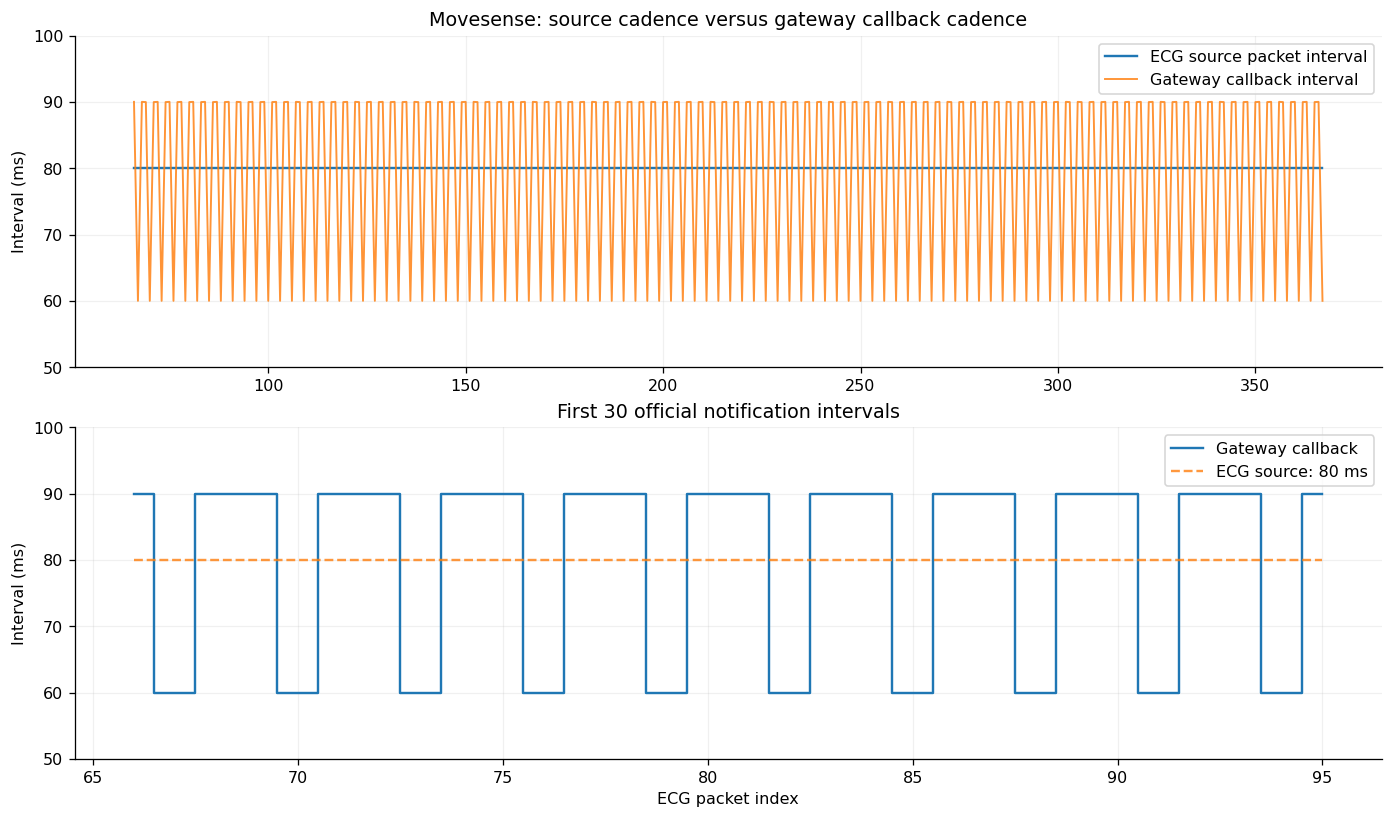

ECG source interval (ms): [80.0]
Gateway callback interval counts (nearest ms):


,count
callback_interval_ms,
60,101
90,201


In [11]:
source_delta_ms = np.diff(pe["source_anchor_us"].to_numpy(dtype=np.int64)) / 1000.0
callback_delta_ms = np.diff(pe["gateway_timestamp_us"].to_numpy(dtype=np.int64)) / 1000.0
packet_number = pe["packet_index"].to_numpy()[1:]

assert np.all(source_delta_ms == 80), "Unexpected non-80 ms ECG source packet interval"
assert np.all(pe["packet_sample_count"] == 16), "Unexpected ECG packet sample count"

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
axes[0].plot(packet_number, source_delta_ms, label="ECG source packet interval", lw=1.5)
axes[0].plot(packet_number, callback_delta_ms, label="Gateway callback interval", lw=1.2, alpha=.83)
axes[0].set(ylabel="Interval (ms)", title="Movesense: source cadence versus gateway callback cadence", ylim=(50, 100))
axes[0].legend(loc="upper right")
mask = packet_number < packet_number[0] + 30
axes[1].step(packet_number[mask], callback_delta_ms[mask], where="mid", label="Gateway callback")
axes[1].plot(packet_number[mask], source_delta_ms[mask], "--", alpha=.8, label="ECG source: 80 ms")
axes[1].set(xlabel="ECG packet index", ylabel="Interval (ms)", title="First 30 official notification intervals", ylim=(50, 100))
axes[1].legend()
plt.show()

interval_counts = pd.Series(np.rint(callback_delta_ms).astype(int)).value_counts().sort_index()
print("ECG source interval (ms):", np.unique(source_delta_ms).tolist())
print("Gateway callback interval counts (nearest ms):")
display(interval_counts.rename_axis("callback_interval_ms").rename("count").to_frame())

The reported BLE connection interval is **30 ms**, while the ECG packet production interval is **80 ms**. Their relative phase therefore cycles: three 80 ms source periods span 240 ms, equal to eight 30 ms BLE intervals. An idealised delivery sequence can alternate **90 → 60 → 90 ms** (with the ordering depending on where the sequence begins).

This is evidence of structured BLE scheduling, **not a direct measurement of radio transmission time**.

## 3. Observed prediction errors by packet phase

Each official ECG packet has one ClockMesh timing observation, although it contains 16 ECG samples. Group the **pre-update prediction error** by the packet index modulo three. The grouping is purely by packet order, so it does not use the residual values to select or adjust phases.

,n,mean_ms,sigma_ms,min_ms,max_ms
phase,,,,,
0,101,-0.3684,0.1182,-0.4906,-0.0003
1,101,9.6405,0.1168,9.5253,10.0057
2,101,-10.3628,0.1132,-10.4753,-10.0123


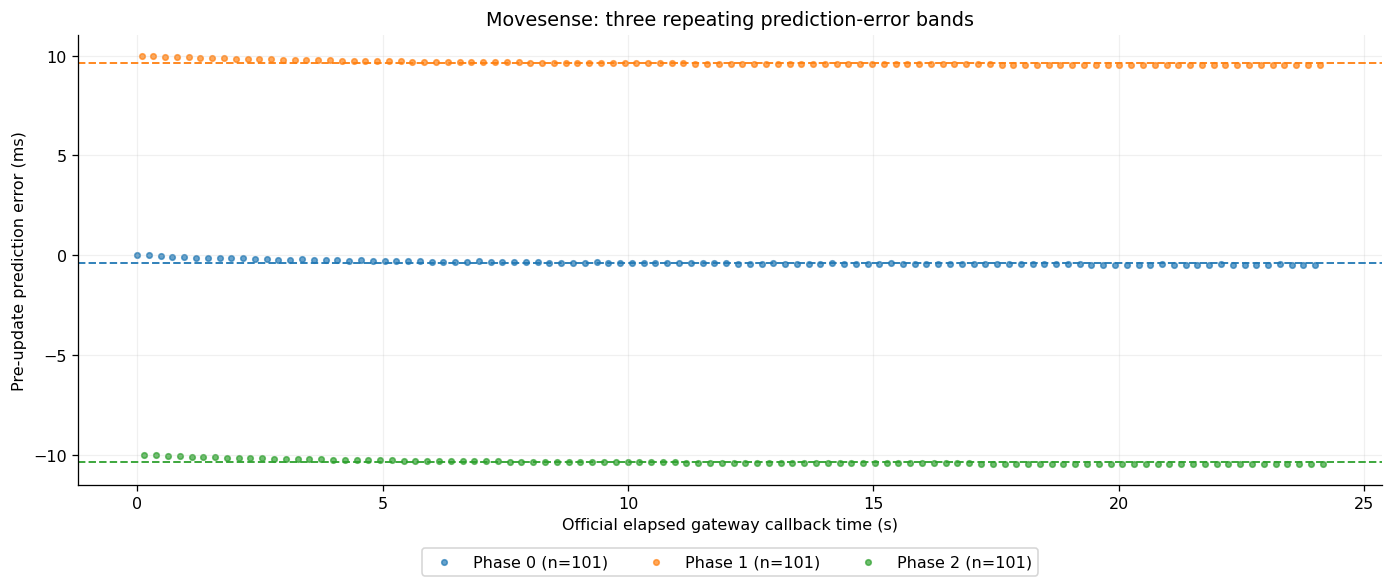

In [12]:
pe["phase"] = (pe["packet_index"].astype(int) - int(pe["packet_index"].min())) % 3
pe["residual_ms"] = pe["latest_prediction_error_ns"].astype(float) / 1e6
pe["callback_elapsed_s"] = (pe["reference_time_ns"].astype("int64") - int(pe["reference_time_ns"].min())) / 1e9

phase_stats = (
    pe.groupby("phase")["residual_ms"]
    .agg(n="size", mean_ms="mean", sigma_ms=lambda x: x.std(ddof=0), min_ms="min", max_ms="max")
)
display(phase_stats.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
phase_colors = plt.get_cmap("tab10")
for phase, g in pe.groupby("phase"):
    color = phase_colors(phase)
    ax.scatter(g["callback_elapsed_s"], g["residual_ms"], s=12, alpha=.68,
               color=color, label=f"Phase {phase} (n={len(g)})")
    ax.axhline(phase_stats.loc[phase, "mean_ms"], lw=1.25, ls="--", color=color, alpha=.9)
ax.set(title="Movesense: three repeating prediction-error bands", xlabel="Official elapsed gateway callback time (s)",
       ylabel="Pre-update prediction error (ms)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=3)
plt.show()

## 4. Decompose the overall standard deviation

A single standard deviation combines the **distance between the three phase means** with the much smaller **variation within each phase**. For phase \(P\), the population variance decomposition is:

\[
\mathrm{Var}(e) = \mathrm{Var}(\mathbb{E}[e \mid P]) + \mathbb{E}[\mathrm{Var}(e \mid P)]
\]

This lets us distinguish structured scheduling variation from residual variation *conditional on a phase*. The within-phase variation is not automatically sensor-to-gateway timing accuracy; slowly varying model effects and callback processing effects may remain.

,Value (ms)
Quantity,
Overall mean,-0.36353
Overall population σ,8.16713
Between-phase σ equivalent,8.16631
Within-phase σ equivalent,0.11608
Idealised three bands at −10/0/+10 ms: σ,8.16497


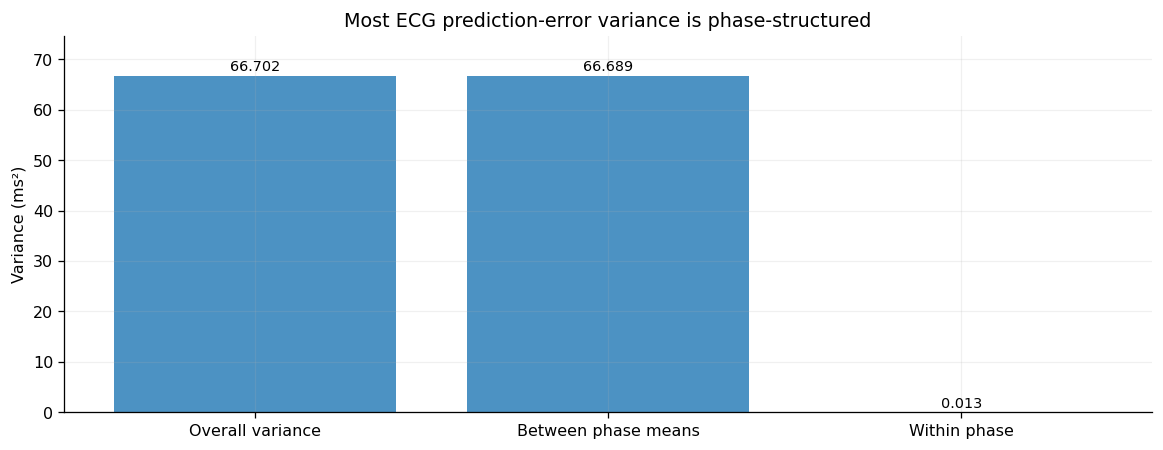

Explained by phase means: 99.9798% of variance
Official ECG callback prediction-error σ: 8.167134 ms


In [13]:
x = pe["residual_ms"].to_numpy()
overall_mean = float(np.mean(x))
overall_sigma = float(np.std(x, ddof=0))
phase_groups = [g["residual_ms"].to_numpy() for _, g in pe.groupby("phase")]
weights = np.array([len(g) for g in phase_groups], dtype=float)
weights /= weights.sum()
phase_means = np.array([g.mean() for g in phase_groups])
phase_variances = np.array([g.var(ddof=0) for g in phase_groups])
between_variance = np.sum(weights * (phase_means - overall_mean)**2)
within_variance = np.sum(weights * phase_variances)
assert np.isclose(overall_sigma**2, between_variance + within_variance)

variance_table = pd.DataFrame({
    "Quantity": ["Overall mean", "Overall population σ", "Between-phase σ equivalent", "Within-phase σ equivalent", "Idealised three bands at −10/0/+10 ms: σ"],
    "Value (ms)": [overall_mean, overall_sigma, np.sqrt(between_variance), np.sqrt(within_variance), np.sqrt(2/3)*10],
})
display(variance_table.round(5).set_index("Quantity"))

fig, ax = plt.subplots(figsize=(10, 3.8))
labels = ["Overall variance", "Between phase means", "Within phase"]
vals = [overall_sigma**2, between_variance, within_variance]
ax.bar(labels, vals, alpha=.8)
ax.set(ylabel="Variance (ms²)", title="Most ECG prediction-error variance is phase-structured")
for i, v in enumerate(vals):
    ax.text(i, v + max(vals)*.015, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylim(0, max(vals)*1.12)
plt.show()

print(f"Explained by phase means: {between_variance / (overall_sigma**2):.4%} of variance")
print(f"Official ECG callback prediction-error σ: {overall_sigma:.6f} ms")

## 5. Check recurrence explicitly

The modulo-three bands are also visible as **lag-three autocorrelation**. A high lag-three correlation confirms that each error tends to resemble the error three packets earlier. Lag-one and lag-two correlations should behave differently.

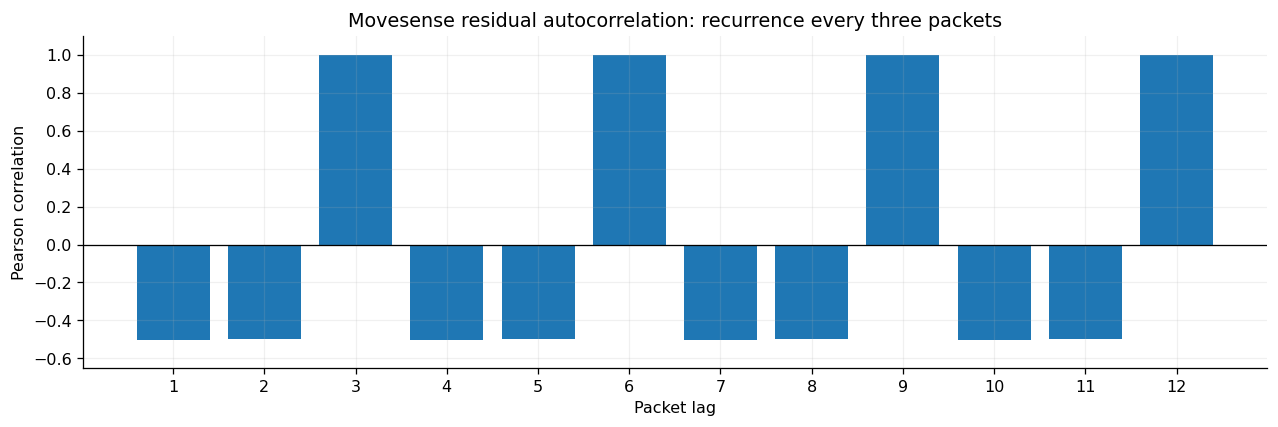

Lag 1 = -0.500798; lag 2 = -0.498497; lag 3 = +0.999999


In [15]:
def serial_corr(values, lag):
    a = np.asarray(values, dtype=float)
    return float(np.corrcoef(a[:-lag], a[lag:])[0, 1])

lags = np.arange(1, 13)
correlations = [serial_corr(x, int(k)) for k in lags]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(lags, correlations)
ax.set(xlabel="Packet lag", ylabel="Pearson correlation", title="Movesense residual autocorrelation: recurrence every three packets",
       xticks=lags, ylim=(-.65, 1.10))
ax.axhline(0, color="black", lw=.8)
plt.show()
print(f"Lag 1 = {correlations[0]:+.6f}; lag 2 = {correlations[1]:+.6f}; lag 3 = {correlations[2]:+.6f}")

## 6. DOT timing under the same gateway load

The DOTs produce samples at approximately 60 Hz (16.667 ms), while their BLE connection intervals are also 30 ms. Nine 60 Hz sample periods take approximately 150 ms, equal to five BLE intervals. This creates a **nominal nine-sample phase recurrence**, although reception batching, scheduling deferrals and model updates can disturb the exact pattern.

The next chart reports the **observed** callback gaps and lag-nine residual correlations; it does not assume every group of nine follows an identical arrival sequence.

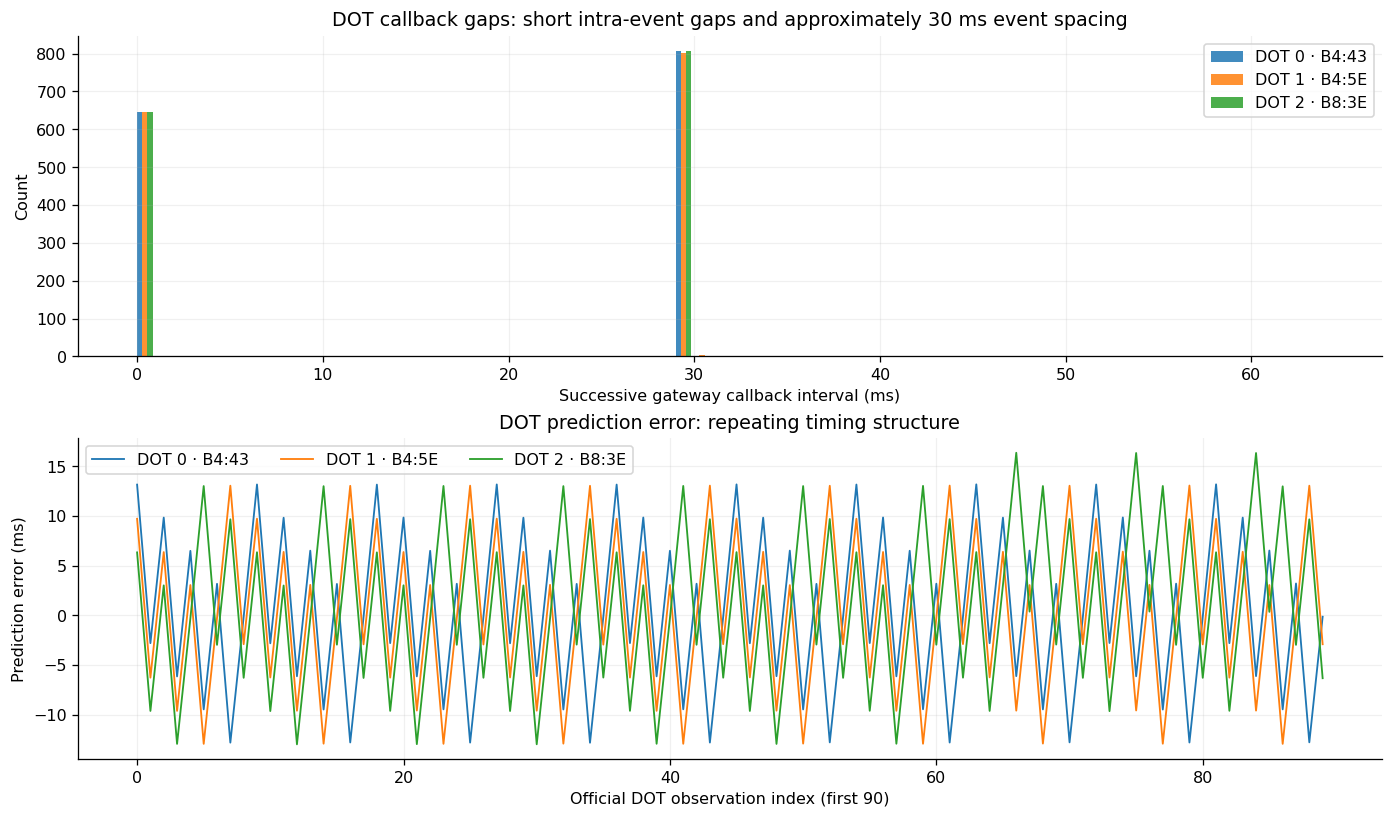

,official_n,mean_residual_ms,population_sigma_ms,lag9_correlation
sensor,,,,
DOT 0 · B4:43,1454,1.1491,8.4045,0.9663
DOT 1 · B4:5E,1454,1.1259,8.4071,0.9495
DOT 2 · B8:3E,1454,0.3205,8.4456,0.9917


In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
records = []
for i, (sensor_id, g) in enumerate(de.groupby("sensor_id", sort=True)):
    g = g.sort_values("raw_dot_timestamp_us")
    label = f"DOT {sensor_id} · {g['address'].iloc[0][-5:]}"
    cb_ms = np.diff(g["gateway_timestamp_us"].to_numpy(dtype=np.int64)) / 1000
    rr = g["latest_prediction_error_ns"].to_numpy(dtype=float) / 1e6
    bins = np.arange(0, 65, 1)
    counts, edges = np.histogram(cb_ms, bins=bins)
    
    axes[0].bar(
        edges[:-1] + i * 0.28,
        counts,
        width=0.28,
        alpha=0.85,
        label=label,
        align="edge",
    )
    axes[1].plot(np.arange(min(90, len(rr))), rr[:90], lw=1.15, label=label)
    records.append({"sensor": label, "official_n": len(g),
                    "mean_residual_ms": rr.mean(), "population_sigma_ms": rr.std(ddof=0),
                    "lag9_correlation": serial_corr(rr, 9)})
axes[0].set(xlabel="Successive gateway callback interval (ms)", ylabel="Count",
            title="DOT callback gaps: short intra-event gaps and approximately 30 ms event spacing")
axes[0].legend()
axes[1].set(xlabel="Official DOT observation index (first 90)", ylabel="Prediction error (ms)",
            title="DOT prediction error: repeating timing structure")
axes[1].legend(ncol=3)
plt.show()
display(pd.DataFrame(records).set_index("sensor").round(4))

/tmp/ipykernel_108335/650028644.py:64: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


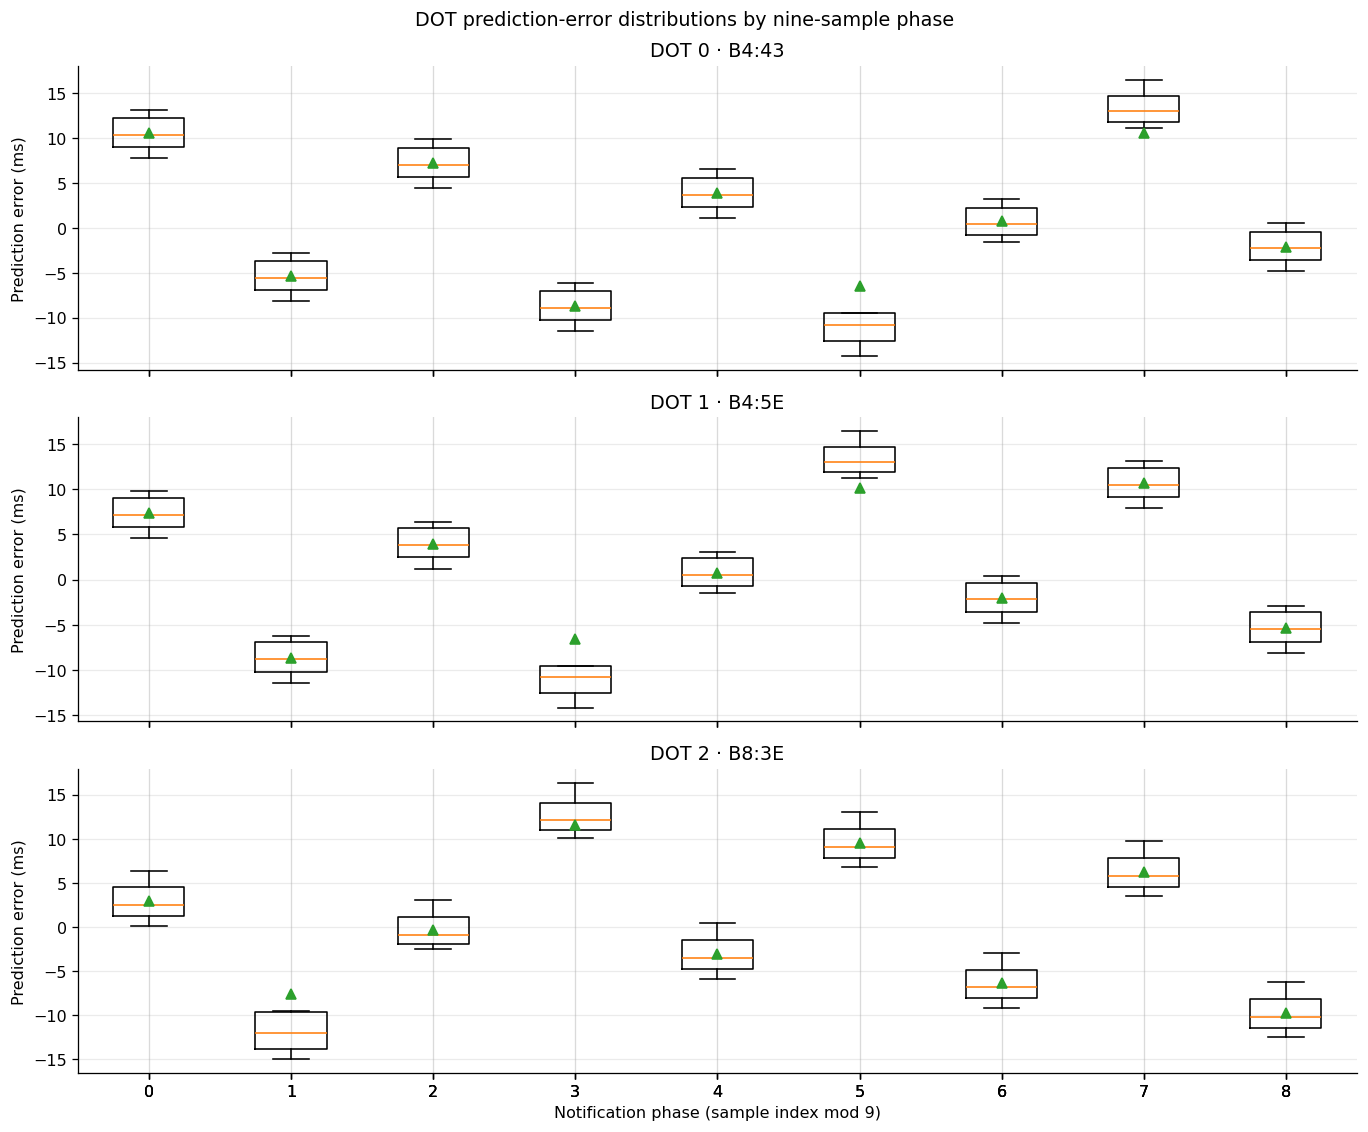

Variance decomposition


,overall_sigma_ms,between_phase_sigma_ms,within_phase_sigma_ms,between_variance_pct,within_variance_pct
sensor,,,,,
DOT 0 · B4:43,8.4045,6.9355,4.7471,68.0974,31.9026
DOT 1 · B4:5E,8.4071,6.8827,4.8278,67.0238,32.9762
DOT 2 · B8:3E,8.4456,7.2808,4.2799,74.3186,25.6814


Statistics for each of the nine phases


n  mean_ms  sigma_ms   min_ms   max_ms
sensor        phase                                          
DOT 0 · B4:43 0      162  10.5786    1.7428   7.8184  13.1962
              1      162  -5.4038    1.7431  -8.1800  -2.7820
              2      162   7.2378    1.7433   4.4617   9.8635
              3      162  -8.7452    1.7441 -11.5047  -6.1167
              4      162   3.9006    1.7395   1.1370   6.5287
              5      161  -6.4270   10.5460 -14.2838  15.8179
              6      161   0.7175    1.5789  -1.6099   3.2085
              7      161  10.6258    8.4761 -13.1443  16.5242
              8      161  -2.1542    1.6371  -4.8233   0.5513
DOT 1 · B4:5E 0      162   7.3161    1.7120   4.5707   9.7454
              1      162  -8.6779    1.7122 -11.4277  -6.2462
              2      162   3.9848    1.7121   1.2140   6.4228
              3      162  -6.5822   10.3875 -14.1477  15.7424
              4      162   0.7739    1.5580  -1.4737   3.0910
              5      161  10.1572    9.0678 -13.1180  16.4084
              6      161  -2.0869    1.5974  -4.7462   0.4454
              7      161  10.6475    1.7095   7.8954  13.0903
              8      161  -5.3450    1.7118  -8.1030  -2.8969
DOT 2 · B8:3E 0      162   2.8833    1.9584   0.1253   6.3700
              1      162  -7.6709   10.3897 -15.0272  14.2464
              2      162  -0.3220    1.8232  -2.5267   3.0528
              3      162  11.6013    5.5252 -12.9885  16.3703
              4      162  -3.1447    1.9103  -5.8827   0.3822
              5      161   9.5430    1.9523   6.8053  13.0361
              6      161  -6.4358    1.9511  -9.1927  -2.9436
              7      161   6.2006    1.9503   3.4493   9.7010
              8      161  -9.7811    1.9492 -12.5167  -6.2666

In [19]:
# DOT nine-phase prediction-error variance decomposition

phase_tables = []
variance_results = []

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for ax, (sensor_id, g) in zip(axes, de.groupby("sensor_id", sort=True)):
    g = g.sort_values("raw_dot_timestamp_us").reset_index(drop=True)
    label = f"DOT {sensor_id} · {g['address'].iloc[0][-5:]}"

    errors = g["latest_prediction_error_ns"].to_numpy(dtype=float) / 1e6
    phases = np.arange(len(errors)) % 9

    df = pd.DataFrame({"phase": phases, "error_ms": errors})

    stats = df.groupby("phase")["error_ms"].agg(
        n="count",
        mean_ms="mean",
        sigma_ms=lambda x: x.std(ddof=0),
        min_ms="min",
        max_ms="max",
    )

    # Population variance decomposition
    overall_mean = errors.mean()
    overall_var = errors.var(ddof=0)

    between_var = np.average(
        (stats["mean_ms"] - overall_mean) ** 2,
        weights=stats["n"],
    )

    within_var = np.average(
        stats["sigma_ms"] ** 2,
        weights=stats["n"],
    )

    variance_results.append({
        "sensor": label,
        "overall_sigma_ms": np.sqrt(overall_var),
        "between_phase_sigma_ms": np.sqrt(between_var),
        "within_phase_sigma_ms": np.sqrt(within_var),
        "between_variance_pct": 100 * between_var / overall_var,
        "within_variance_pct": 100 * within_var / overall_var,
    })

    phase_tables.append(stats.assign(sensor=label).reset_index())

    # Distribution of prediction errors within each phase
    ax.boxplot(
        [errors[phases == p] for p in range(9)],
        positions=np.arange(9),
        showfliers=False,
        showmeans=True,
    )

    ax.set_title(label)
    ax.set_ylabel("Prediction error (ms)")
    ax.grid(axis="y", alpha=0.25)

axes[-1].set_xlabel("Notification phase (sample index mod 9)")
plt.suptitle("DOT prediction-error distributions by nine-sample phase")
plt.tight_layout()
plt.show()

print("Variance decomposition")
display(
    pd.DataFrame(variance_results)
    .set_index("sensor")
    .round(4)
)

print("Statistics for each of the nine phases")
display(
    pd.concat(phase_tables, ignore_index=True)
    .set_index(["sensor", "phase"])
    .round(4)
)

DOT 0, phase 5: 5 changes greater than 20 ms
DOT 0, phase 7: 3 changes greater than 20 ms
DOT 1, phase 3: 7 changes greater than 20 ms
DOT 1, phase 5: 5 changes greater than 20 ms
DOT 2, phase 1: 1 changes greater than 20 ms
DOT 2, phase 3: 1 changes greater than 20 ms


/tmp/ipykernel_108335/1211077029.py:43: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


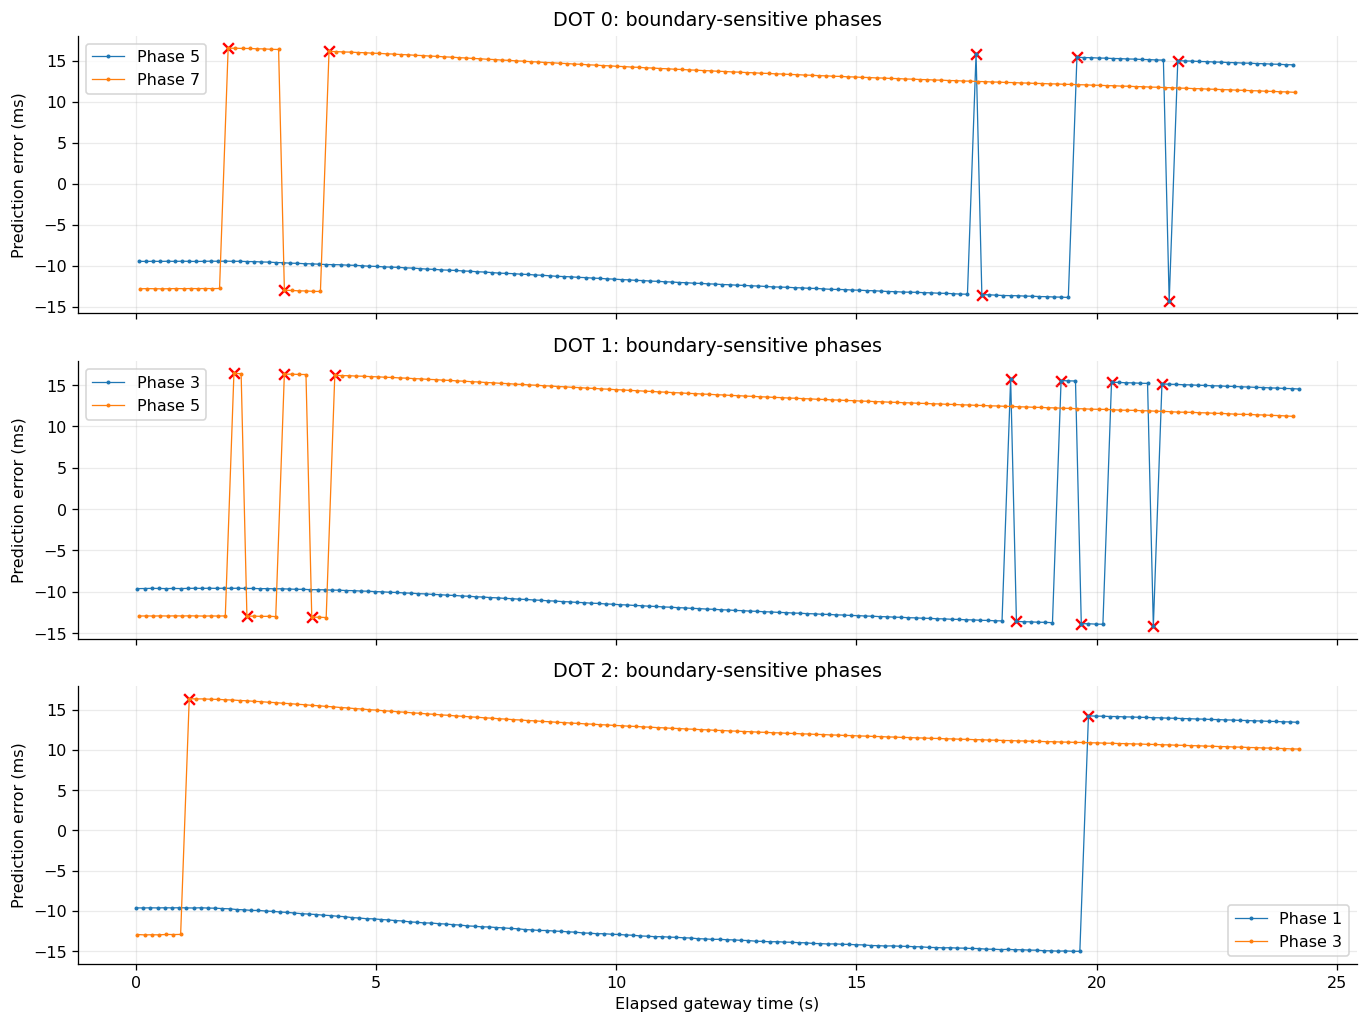

In [20]:
# Examine DOT phases close to BLE connection-event boundaries

boundary_phases = {
    0: [5, 7],
    1: [3, 5],
    2: [1, 3],
}

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (sensor_id, g) in zip(axes, de.groupby("sensor_id", sort=True)):
    g = g.sort_values("raw_dot_timestamp_us").reset_index(drop=True)

    elapsed = (
        g["gateway_timestamp_us"] - g["gateway_timestamp_us"].iloc[0]
    ) / 1e6

    errors = g["latest_prediction_error_ns"] / 1e6
    phases = np.arange(len(g)) % 9

    for phase in boundary_phases[sensor_id]:
        mask = phases == phase
        t = elapsed[mask].to_numpy()
        e = errors[mask].to_numpy()

        ax.plot(t, e, ".-", markersize=3, linewidth=0.8,
                label=f"Phase {phase}")

        # Identify changes close to one BLE connection interval
        jumps = np.abs(np.diff(e)) > 20
        ax.scatter(t[1:][jumps], e[1:][jumps],
                   marker="x", s=45, color="red")

        print(f"DOT {sensor_id}, phase {phase}: "
              f"{jumps.sum()} changes greater than 20 ms")

    ax.set_title(f"DOT {sensor_id}: boundary-sensitive phases")
    ax.set_ylabel("Prediction error (ms)")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Elapsed gateway time (s)")
plt.tight_layout()
plt.show()

### Connection-event boundary effects

The nine-phase variance decomposition explains approximately 67–74% of the DOT prediction-error variance. However, most individual phases exhibit relatively small variation, while two phases per sensor have substantially larger standard deviations.

These phases appear particularly sensitive to BLE connection-event boundaries. When a notification becomes available close to a connection opportunity, small changes in timing may determine whether it is transmitted during that event or the following one.

With a 30 ms BLE connection interval, this can produce approximately 30 ms differences in gateway callback timing for otherwise equivalent positions in the nine-sample sequence.

The additional analysis examines the affected phases over time and identifies large changes between successive nine-sample cycles.

This behaviour is consistent with connection-event boundary crossing. It should not automatically be interpreted as random timing noise, missed packets or abnormal retransmissions. Confirming the exact mechanism would require radio-level timing observations.

## 7. Compare the four sensor models

This is a comparison of **prediction errors against the BLE gateway callback clock**, not an assessment of independent measurement-time accuracy. The DOT observations are at 60 Hz; the ECG model receives one observation per 16-sample ECG packet (nominally 12.5 Hz).

,type,timing_observations,mean_error_ms,population_sigma_ms
sensor,,,,
DOT 0,Movella DOT,1454,1.1491,8.4045
DOT 1,Movella DOT,1454,1.1259,8.4071
DOT 2,Movella DOT,1454,0.3205,8.4456
Movesense,ECG packet,303,-0.3635,8.1671


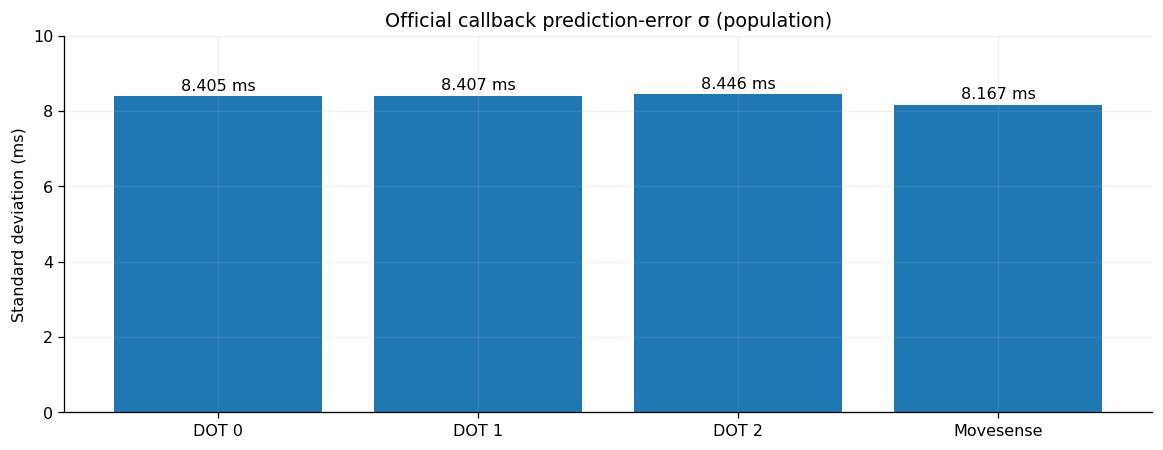

In [18]:
comparison = []
for sensor_id, g in de.groupby("sensor_id", sort=True):
    errors = g["latest_prediction_error_ns"].dropna().to_numpy(dtype=float) / 1e6
    comparison.append({"sensor": f"DOT {sensor_id}", "type": "Movella DOT", "timing_observations": len(errors),
                       "mean_error_ms": errors.mean(), "population_sigma_ms": errors.std(ddof=0)})
ecg_errors = pe["residual_ms"].to_numpy()
comparison.append({"sensor": "Movesense", "type": "ECG packet", "timing_observations": len(ecg_errors),
                   "mean_error_ms": ecg_errors.mean(), "population_sigma_ms": ecg_errors.std(ddof=0)})
result = pd.DataFrame(comparison)
display(result.set_index("sensor").round(4))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(result["sensor"], result["population_sigma_ms"])
ax.set(title="Official callback prediction-error σ (population)", ylabel="Standard deviation (ms)", ylim=(0, 10))
for i, val in enumerate(result["population_sigma_ms"]):
    ax.text(i, val+.15, f"{val:.3f} ms", ha="center")
plt.show()

## Interpretation and limitations

- **Movesense source cadence is exact in this recording:** 80 ms per 16-sample packet. Callback intervals follow a regular approximately 60/90 ms pattern, reflecting the mismatch between 80 ms production and 30 ms connection scheduling.
- **The 8.17 ms total σ is dominated by a three-phase pattern.** Report both overall σ and within-phase σ: reporting only the overall σ could imply incorrectly that almost all of this variation is random.
- **DOTs show a strong nine-sample recurrence**, consistent with their 60 Hz source cadence relative to the 30 ms BLE interval. Unlike the ECG three-phase pattern, the precise DOT phase sequence can be disturbed by event batching/deferrals.
- The three-phase structure is consistent with BLE scheduling but **does not prove the exact radio-level scheduling mechanism** without RF/stack instrumentation.
- All residuals use an accepted time mapping that was continuously updated during official measurement. Phase-conditioned residual σ is therefore **not a calibrated estimate of sensor timestamp accuracy**.
- For a reproducible comparison, keep sensor configuration, streaming load, connection intervals, ClockMesh acceptance rules and the prediction-error definition unchanged across captures.